# Predicting Sales from Influencer Campaign Data

This notebook follows the case-study approach for predicting product sales from messy influencer campaign data.

What we do in this notebook:
1. Clean the raw CSV files
2. Explore the data and relationships
3. Engineer better features
4. Compare regression models
5. Tune the best model
6. Evaluate using RMSE and R2
7. Build a reusable prediction pipeline

## Cell 1: Import libraries

This cell imports the packages needed for data cleaning, visualization, modeling, and evaluation.

In [1]:
# Import required libraries for data analysis and machine learning
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, RandomizedSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

try:
    from xgboost import XGBRegressor
    HAS_XGB = True
except ImportError:
    HAS_XGB = False
    print('XGBoost not installed. Falling back to GradientBoosting.')

pd.set_option('display.max_columns', None)
sns.set(style='whitegrid')
RANDOM_STATE = 42

print('Libraries imported successfully.')

Libraries imported successfully.


## Cell 2: Load the training and test data

This cell reads the messy CSV files into pandas DataFrames so the data can be cleaned and modeled.

In [2]:
#Downloading the train data
!gdown 17mNOMu0x-8Br9t3J2f0dcLrfq24eWv5Z

#Downloading the test data
!gdown 1m3ZO0DctdhpAsF2eyZcKxswkZ5VuurRa

Downloading...
From: https://drive.google.com/uc?id=17mNOMu0x-8Br9t3J2f0dcLrfq24eWv5Z
To: /content/messy_train_data.csv
100% 709k/709k [00:00<00:00, 18.1MB/s]
Downloading...
From: https://drive.google.com/uc?id=1m3ZO0DctdhpAsF2eyZcKxswkZ5VuurRa
To: /content/messy_test_data.csv
100% 162k/162k [00:00<00:00, 16.9MB/s]


In [24]:
# Load the raw training and test datasets
train_raw = pd.read_csv('messy_train_data.csv')
test_raw = pd.read_csv('messy_test_data.csv')

print('Train shape:', train_raw.shape)
print('Test shape:', test_raw.shape)
print('Preview of the training data:')
train_raw.head()

Train shape: (8000, 8)
Test shape: (2000, 7)
Preview of the training data:


,Followers,EngagementRate (%),AdSpend (GBP),ContentQuality,Sales (Units),ID,Timestamp,Notes
0,106572.0,2.573174871146172,2614.3781948587675,5.275680,6340,9254,2021-11-27,Pending
1,77583.0,0.9394984315675532,4975.962514379572,8.756268,5793,1561,2022-02-13,Review
2,92832.0,2.1761012652155296,4107.769534318886,6.454727,8104,1670,2023-09-25,Pending
3,53565.0,1.4783757541486553,4293.330464613049,4.312813,7293,6087,2023-02-15,Review
4,121079.0,3.3741976179329356,5343.549440897207,3.769047,14396,6669,2023-05-28,NaN


In [27]:
#Checking if any duplicates the train data
train_raw.duplicated().sum()

np.int64(0)

In [4]:
# Check data types and missing values before cleaning
train_raw.info()
print('Missing values per column:')
print(train_raw.isna().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Followers           7840 non-null   float64
 1   EngagementRate (%)  7840 non-null   object 
 2   AdSpend (GBP)       7841 non-null   object 
 3   ContentQuality      7840 non-null   float64
 4   Sales (Units)       8000 non-null   int64  
 5   ID                  8000 non-null   int64  
 6   Timestamp           8000 non-null   object 
 7   Notes               5348 non-null   object 
dtypes: float64(2), int64(2), object(4)
memory usage: 500.1+ KB
Missing values per column:
Followers              160
EngagementRate (%)     160
AdSpend (GBP)          159
ContentQuality         160
Sales (Units)            0
ID                       0
Timestamp                0
Notes                 2652
dtype: int64


## Cell 3: Data cleaning function

The raw data is messy: values include currency symbols, percentage signs, missing values, negative spend, and impossible follower counts. This cleaning step standardizes the columns before modeling.

In [5]:
# Function to clean numeric strings such as currency and percentage values
def clean_numeric_string(x):
    if pd.isna(x):
        return np.nan
    if isinstance(x, (int, float)):
        return float(x)
    s = str(x).strip()
    s = s.replace(chr(163), '').replace(',', '').replace('%', '')
    try:
        return float(s)
    except ValueError:
        return np.nan

# Main cleaning function applied to the full dataframe
def clean_campaign_data(df):
    df = df.copy()

    # Convert messy numeric-like columns to clean floats
    for col in ['Followers', 'EngagementRate (%)', 'AdSpend (GBP)', 'ContentQuality']:
        if col in df.columns:
            df[col] = df[col].apply(clean_numeric_string)

    # --- IQR OUTLIER REMOVAL ---
    # Apply IQR filtering to key numerical columns to filter extreme values
    iqr_cols = ['Followers', 'EngagementRate (%)', 'AdSpend (GBP)', 'ContentQuality']
    for col in iqr_cols:
        if col in df.columns:
            Q1 = df[col].quantile(0.25)
            Q3 = df[col].quantile(0.75)
            IQR = Q3 - Q1
            lower_bound = Q1 - (1.5 * IQR)
            upper_bound = Q3 + (1.5 * IQR)
            # Set outliers outside the bounds to NaN
            df.loc[(df[col] < lower_bound) | (df[col] > upper_bound), col] = np.nan

    # # Parse timestamp into month and year to capture seasonality
    # if 'Timestamp' in df.columns:
    #     df['Timestamp'] = pd.to_datetime(df['Timestamp'], errors='coerce')
    #     df['campaign_month'] = df['Timestamp'].dt.month
    #     df['campaign_year'] = df['Timestamp'].dt.year

    # Drop noisy or non-predictive columns
    drop_cols = [c for c in ['Notes', 'ID', 'Timestamp'] if c in df.columns]
    df = df.drop(columns=drop_cols)

    return df

# Apply cleaning to both train and test data
train_clean = clean_campaign_data(train_raw)
test_clean = clean_campaign_data(test_raw)

print('Cleaned train shape:', train_clean.shape)
print('Cleaned test shape:', test_clean.shape)
train_clean.head()

Cleaned train shape: (8000, 5)
Cleaned test shape: (2000, 4)


,Followers,EngagementRate (%),AdSpend (GBP),ContentQuality,Sales (Units)
0,106572.0,2.573175,2614.378195,5.275680,6340
1,77583.0,0.939498,4975.962514,8.756268,5793
2,92832.0,2.176101,4107.769534,6.454727,8104
3,53565.0,1.478376,4293.330465,4.312813,7293
4,121079.0,3.374198,5343.549441,3.769047,14396


In [6]:
train_clean = train_clean.dropna(subset = ['Followers', 'EngagementRate (%)','AdSpend (GBP)', 'ContentQuality'])
train_clean = train_clean.reset_index(drop = True)
train_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7143 entries, 0 to 7142
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Followers           7143 non-null   float64
 1   EngagementRate (%)  7143 non-null   float64
 2   AdSpend (GBP)       7143 non-null   float64
 3   ContentQuality      7143 non-null   float64
 4   Sales (Units)       7143 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 279.2 KB


In [7]:
# Inspect remaining missing values after cleaning
print('Missing values after cleaning (train):')
print(train_clean.isna().sum())
print('Missing values after cleaning (test):')
print(test_clean.isna().sum())

Missing values after cleaning (train):
Followers             0
EngagementRate (%)    0
AdSpend (GBP)         0
ContentQuality        0
Sales (Units)         0
dtype: int64
Missing values after cleaning (test):
Followers             47
EngagementRate (%)    43
AdSpend (GBP)         48
ContentQuality        40
dtype: int64


## Cell 4: Exploratory Data Analysis

This cell explores the relationship between campaign features and sales to understand which variables matter most.

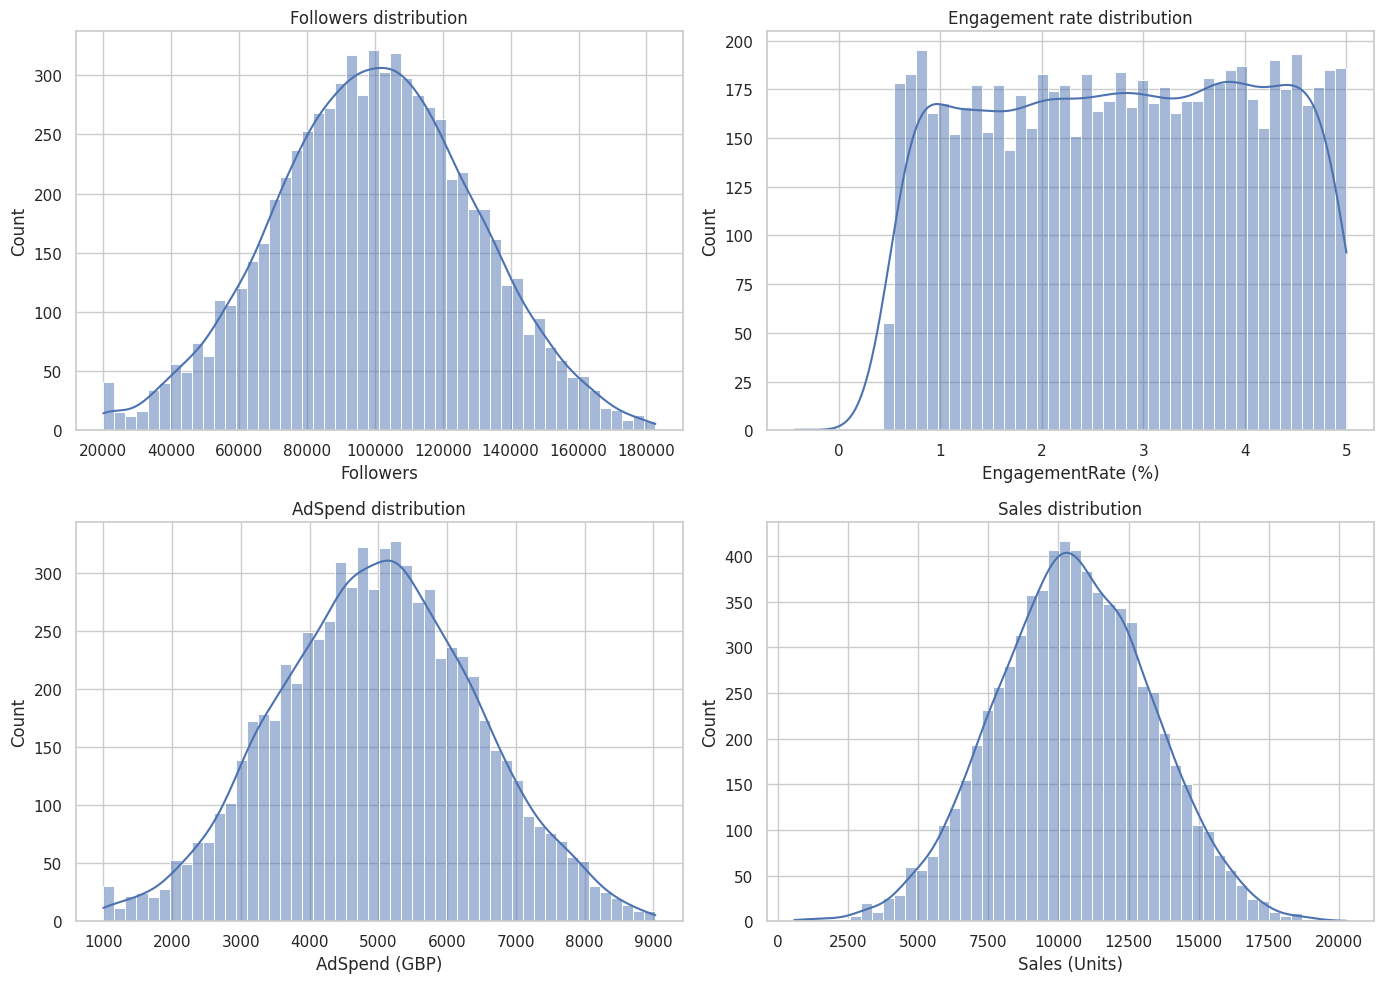

In [8]:
# Plot the distribution of each numeric feature
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
sns.histplot(train_clean['Followers'].dropna(), bins=50, ax=axes[0, 0], kde=True)
axes[0, 0].set_title('Followers distribution')
sns.histplot(train_clean['EngagementRate (%)'].dropna(), bins=50, ax=axes[0, 1], kde=True)
axes[0, 1].set_title('Engagement rate distribution')
sns.histplot(train_clean['AdSpend (GBP)'].dropna(), bins=50, ax=axes[1, 0], kde=True)
axes[1, 0].set_title('AdSpend distribution')
sns.histplot(train_clean['Sales (Units)'].dropna(), bins=50, ax=axes[1, 1], kde=True)
axes[1, 1].set_title('Sales distribution')
plt.tight_layout()
plt.show()

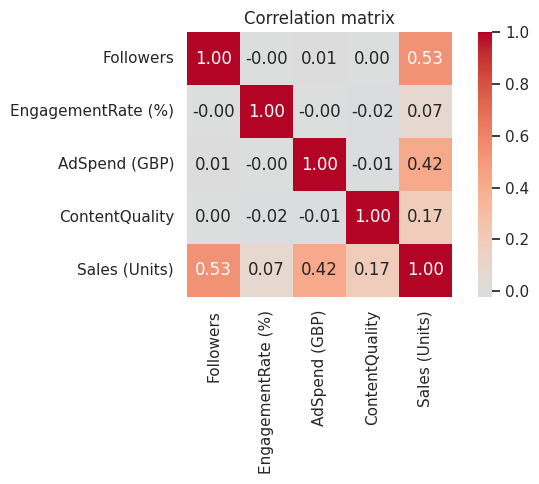

Correlation with Sales:
Sales (Units)         1.000000
Followers             0.534957
AdSpend (GBP)         0.416039
ContentQuality        0.173864
EngagementRate (%)    0.074835
Name: Sales (Units), dtype: float64


In [9]:
# Compute correlations to check which features move together with Sales
num_cols = ['Followers', 'EngagementRate (%)', 'AdSpend (GBP)', 'ContentQuality', 'Sales (Units)']
corr = train_clean[num_cols].corr()
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap='coolwarm', center=0, fmt='.2f', square=True)
plt.title('Correlation matrix')
plt.tight_layout()
plt.show()
print('Correlation with Sales:')
print(corr['Sales (Units)'].sort_values(ascending=False))

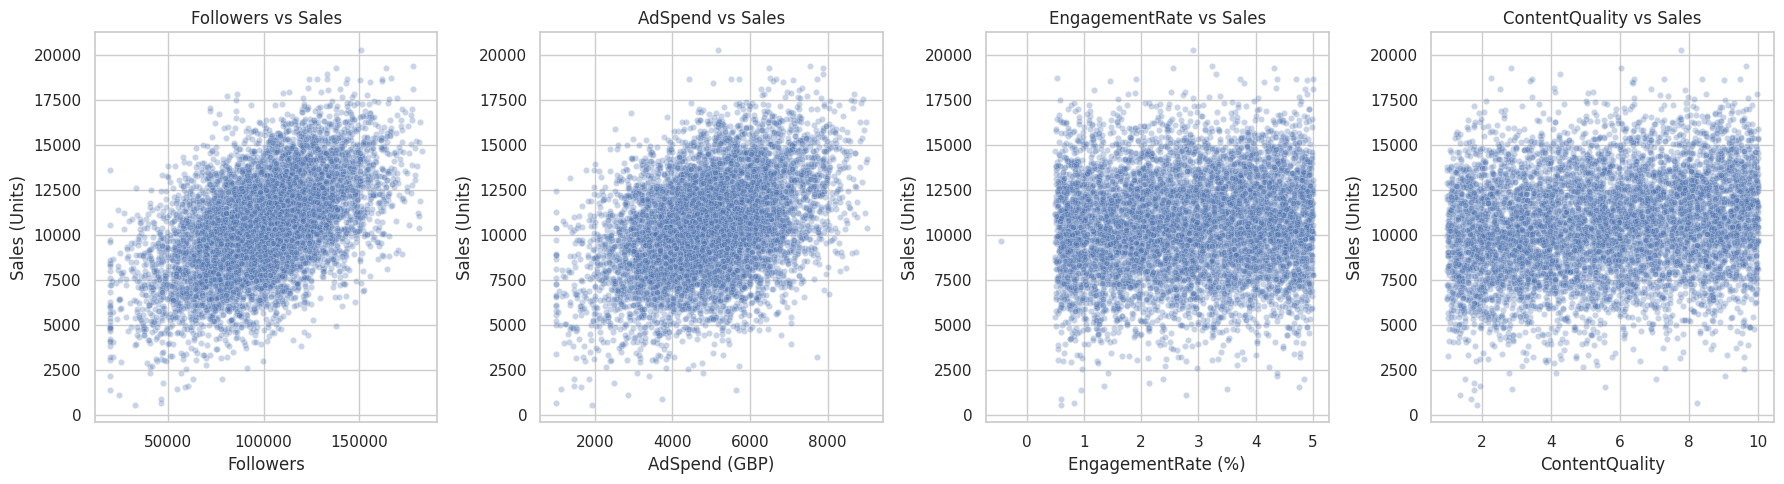

In [10]:
# Scatter plots to visualize relationships between features and sales
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
sns.scatterplot(data=train_clean, x='Followers', y='Sales (Units)', ax=axes[0], alpha=0.3, s=20)
axes[0].set_title('Followers vs Sales')
sns.scatterplot(data=train_clean, x='AdSpend (GBP)', y='Sales (Units)', ax=axes[1], alpha=0.3, s=20)
axes[1].set_title('AdSpend vs Sales')
sns.scatterplot(data=train_clean, x='EngagementRate (%)', y='Sales (Units)', ax=axes[2], alpha=0.3, s=20)
axes[2].set_title('EngagementRate vs Sales')
sns.scatterplot(data=train_clean, x='ContentQuality', y='Sales (Units)', ax=axes[3], alpha=0.3, s=20)
axes[3].set_title('ContentQuality vs Sales')
plt.tight_layout()
plt.show()

## Cell 5: Feature engineering

This cell creates better inputs for the model: log transforms for skewed variables and interaction terms that reflect real business logic behind influencer campaigns.

In [11]:
# Create engineered features that often improve predictive performance
def engineer_features(df):
    df = df.copy()

    # Log transforms reduce skew in large-scale variables like followers and spend
    df['log_followers'] = np.log1p(df['Followers'])
    df['log_adspend'] = np.log1p(df['AdSpend (GBP)'])

    # Engaged followers combine follower count and engagement rate
    df['engaged_followers'] = df['Followers'] * (df['EngagementRate (%)'] / 100.0)
    df['log_engaged_followers'] = np.log1p(df['engaged_followers'])

    # Spend efficiency ratio reflects cost per follower reached
    df['spend_per_follower'] = df['AdSpend (GBP)'] / (df['Followers'] + 1)
    return df


# Apply feature engineering to train and test data
train_fe = engineer_features(train_clean)
test_fe = engineer_features(test_clean)

print('Feature-engineered train shape:', train_fe.shape)
new_features = [c for c in train_fe.columns if c not in train_clean.columns]
print('Engineered feature names:', new_features)
train_fe.head()

Feature-engineered train shape: (7143, 10)
Engineered feature names: ['log_followers', 'log_adspend', 'engaged_followers', 'log_engaged_followers', 'spend_per_follower']


/usr/local/lib/python3.13/dist-packages/pandas/core/arraylike.py:399: RuntimeWarning: invalid value encountered in log1p
  result = getattr(ufunc, method)(*inputs, **kwargs)


,Followers,EngagementRate (%),AdSpend (GBP),ContentQuality,Sales (Units),log_followers,log_adspend,engaged_followers,log_engaged_followers,spend_per_follower
0,106572.0,2.573175,2614.378195,5.275680,6340,11.576585,7.869164,2742.283924,7.916911,0.024531
1,77583.0,0.939498,4975.962514,8.756268,5793,11.259116,8.512575,728.891068,6.592895,0.064136
2,92832.0,2.176101,4107.769534,6.454727,8104,11.438557,8.320879,2020.118327,7.611406,0.044249
3,53565.0,1.478376,4293.330465,4.312813,7293,10.888670,8.365051,791.891973,6.675687,0.080150
4,121079.0,3.374198,5343.549441,3.769047,14396,11.704207,8.583833,4085.444734,8.315431,0.044132


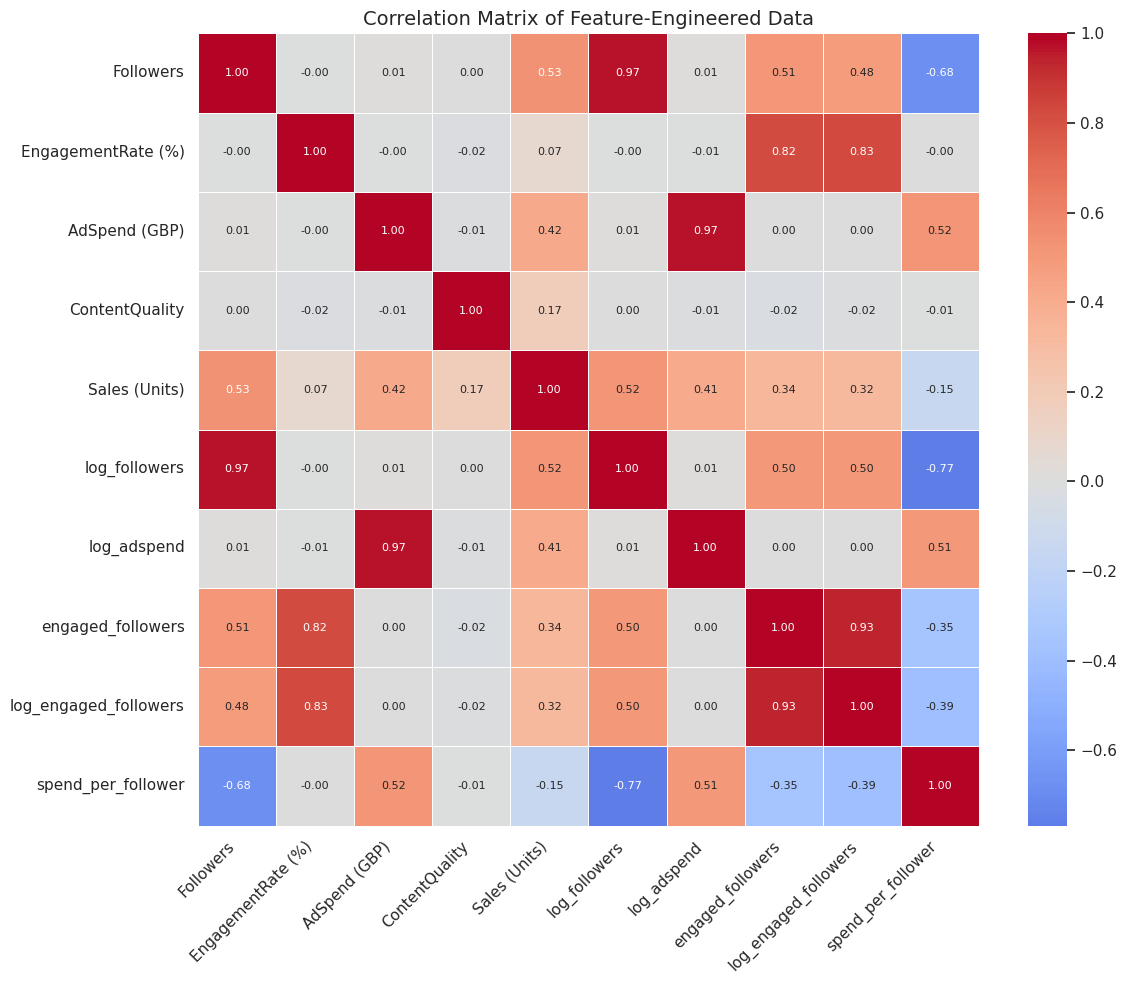

In [12]:
#Check the correlation of new features
plt.figure(figsize=(12, 10))
sns.heatmap(
    train_fe.corr(),
    annot=True,
    cmap='coolwarm',
    center=0,
    fmt='.2f',
    linewidths=0.5,
    annot_kws={"size": 8}
)
plt.title('Correlation Matrix of Feature-Engineered Data', fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [13]:
# Function to drop highly correlated features
def remove_high_collinear_features(df, target_col='Sales (Units)', threshold=0.85):
    df_clean = df.copy()

    # Separate features from target if target exists in the dataframe
    if target_col in df_clean.columns:
        y = df_clean[target_col]
        X = df_clean.drop(columns=[target_col])
    else:
        X = df_clean

    # Calculate the correlation matrix
    corr_matrix = X.corr().abs()

    # Create an upper triangle mask to avoid redundant checks
    upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

    # Find features with correlation greater than the threshold
    to_drop = [column for column in upper_tri.columns if any(upper_tri[column] > threshold)]

    print(f"Features dropped due to high collinearity (> {threshold}):", to_drop)

    # Drop the features from X
    X_reduced = X.drop(columns=to_drop)

    # Re-attach target if it was present
    if target_col in df_clean.columns:
        X_reduced[target_col] = y

    return X_reduced

# Apply to your feature-engineered training data
train_fe = remove_high_collinear_features(train_fe, target_col='Sales (Units)', threshold=0.85)

print("New train_fe shape:", train_fe.shape)

Features dropped due to high collinearity (> 0.85): ['log_followers', 'log_adspend', 'log_engaged_followers']
New train_fe shape: (7143, 7)


In [14]:
train_fe.head()

,Followers,EngagementRate (%),AdSpend (GBP),ContentQuality,engaged_followers,spend_per_follower,Sales (Units)
0,106572.0,2.573175,2614.378195,5.275680,2742.283924,0.024531,6340
1,77583.0,0.939498,4975.962514,8.756268,728.891068,0.064136,5793
2,92832.0,2.176101,4107.769534,6.454727,2020.118327,0.044249,8104
3,53565.0,1.478376,4293.330465,4.312813,791.891973,0.080150,7293
4,121079.0,3.374198,5343.549441,3.769047,4085.444734,0.044132,14396


## Cell 6: Train and validation split with preprocessing

This cell splits the data into training and validation sets and applies median imputation plus robust scaling.

In [15]:
# Define target and feature columns
target_col = 'Sales (Units)'
feature_cols = [c for c in train_fe.columns if c != target_col]
X = train_fe[feature_cols]
y = train_fe[target_col]

# Split into train and validation sets
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE
)

print('Training set shape:', X_train.shape)
print('Validation set shape:', X_val.shape)

# Preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', Pipeline(steps=[
            ('scaler', StandardScaler())
        ]), feature_cols)
    ]
)

print('Preprocessing pipeline created.')

Training set shape: (5357, 6)
Validation set shape: (1786, 6)
Preprocessing pipeline created.


## Cell 7: Baseline models

This cell compares a few regression models on the validation set to see which family performs best on this data.

In [16]:
# Function to fit and evaluate a model pipeline on validation data
def evaluate(model, X_tr, y_tr, X_v, y_v, name='model'):
    model.fit(X_tr, y_tr)
    preds = model.predict(X_v)
    preds = np.clip(preds, 0, None)
    rmse = np.sqrt(mean_squared_error(y_v, preds))
    mae = mean_absolute_error(y_v, preds)
    r2 = r2_score(y_v, preds)
    print(name, '| RMSE =', round(rmse, 2), ' MAE =', round(mae, 2), ' R2 =', round(r2, 4))
    return rmse, mae, r2


# Ridge regression as a simple linear baseline
ridge_pipe = Pipeline(steps=[
    ('preprocess', preprocessor),
    ('model', Ridge(alpha=1.0, random_state=RANDOM_STATE))
])
evaluate(ridge_pipe, X_train, y_train, X_val, y_val, 'Ridge (baseline)')

# Random forest regressor
rf_pipe = Pipeline(steps=[
    ('preprocess', preprocessor),
    ('model', RandomForestRegressor(
        n_estimators=300,
        max_depth=12,
        min_samples_leaf=3,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])
evaluate(rf_pipe, X_train, y_train, X_val, y_val, 'RandomForest')

# Gradient boosting regressor
gbr_pipe = Pipeline(steps=[
    ('preprocess', preprocessor),
    ('model', GradientBoostingRegressor(
        n_estimators=300,
        max_depth=3,
        learning_rate=0.05,
        random_state=RANDOM_STATE
    ))
])
evaluate(gbr_pipe, X_train, y_train, X_val, y_val, 'GradientBoosting')

# XGBoost regressor if installed
if HAS_XGB:
    xgb_pipe = Pipeline(steps=[
        ('preprocess', preprocessor),
        ('model', XGBRegressor(
            n_estimators=300,
            max_depth=4,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            objective='reg:squarederror',
            random_state=RANDOM_STATE,
            verbosity=0
        ))
    ])
    evaluate(xgb_pipe, X_train, y_train, X_val, y_val, 'XGBoost')

Ridge (baseline) | RMSE = 1975.45  MAE = 1580.98  R2 = 0.4862
RandomForest | RMSE = 2028.87  MAE = 1625.14  R2 = 0.458
GradientBoosting | RMSE = 2003.15  MAE = 1599.87  R2 = 0.4717
XGBoost | RMSE = 2015.91  MAE = 1609.6  R2 = 0.4649


## Cell 8: Hyperparameter tuning with RandomizedSearchCV

This cell tunes the best-performing model family using cross-validation to reduce overfitting and improve generalization.

In [17]:
# Choose XGBoost if available as the tuning candidate, otherwise GradientBoosting
if HAS_XGB:
    base_model = XGBRegressor(random_state=RANDOM_STATE, objective='reg:squarederror', verbosity=0)
    param_dist = {
        'model__n_estimators': [200, 300, 400, 600],
        'model__max_depth': [2, 3, 4, 5, 6],
        'model__learning_rate': [0.01, 0.03, 0.05, 0.1],
        'model__subsample': [0.7, 0.8, 0.9],
        'model__colsample_bytree': [0.6, 0.7, 0.8, 0.9],
        'model__reg_alpha': [0, 0.01, 0.1, 0.5, 1],
        'model__reg_lambda': [0.5, 1, 2, 3],
        'model__min_child_weight': [1, 3, 5, 7]
    }
else:
    base_model = GradientBoostingRegressor(random_state=RANDOM_STATE)
    param_dist = {
        'model__n_estimators': [200, 300, 400, 600],
        'model__max_depth': [2, 3, 4, 5],
        'model__learning_rate': [0.01, 0.03, 0.05, 0.1],
        'model__subsample': [0.7, 0.8, 0.9]
    }

# Build the tuning pipeline
tuning_pipeline = Pipeline(steps=[
    ('preprocess', preprocessor),
    ('model', base_model)
])

# Use 5-fold cross-validation for robust parameter selection
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

search = RandomizedSearchCV(
    tuning_pipeline,
    param_distributions=param_dist,
    n_iter=30,
    scoring='neg_root_mean_squared_error',
    cv=cv,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1
)

search.fit(X_train, y_train)
print('Best params:', search.best_params_)
print('Best CV RMSE:', -search.best_score_)

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best params: {'model__subsample': 0.7, 'model__reg_lambda': 1, 'model__reg_alpha': 0.01, 'model__n_estimators': 300, 'model__min_child_weight': 5, 'model__max_depth': 2, 'model__learning_rate': 0.03, 'model__colsample_bytree': 0.9}
Best CV RMSE: 1982.5838623046875


In [18]:
# Evaluate the tuned model on the held-out validation set
best_model = search.best_estimator_
evaluate(best_model, X_train, y_train, X_val, y_val, 'Tuned Model')

Tuned Model | RMSE = 1991.34  MAE = 1591.69  R2 = 0.4779


(np.float64(1991.3353559860277), 1591.6900634765625, 0.47790807485580444)

## Cell 9: Cross-validation stability check

This cell measures whether the model performs consistently across multiple folds of the data, which is important for robust model selection.

In [19]:
# Test stability of the tuned model across 5 different folds of the training data
cv_rmse_scores = -cross_val_score(best_model, X, y, cv=cv, scoring='neg_root_mean_squared_error', n_jobs=-1)
cv_r2_scores = cross_val_score(best_model, X, y, cv=cv, scoring='r2', n_jobs=-1)

print('CV RMSE scores:')
for i, score in enumerate(cv_rmse_scores, 1):
    print('Fold', i, ':', round(score, 2))
print('Mean CV RMSE:', cv_rmse_scores.mean(), '+/-', cv_rmse_scores.std())

print('CV R2 scores:')
for i, score in enumerate(cv_r2_scores, 1):
    print('Fold', i, ':', round(score, 4))
print('Mean CV R2:', cv_r2_scores.mean(), '+/-', cv_r2_scores.std())

CV RMSE scores:
Fold 1 : 2010.09
Fold 2 : 1969.17
Fold 3 : 2007.34
Fold 4 : 1977.41
Fold 5 : 1989.69
Mean CV RMSE: 1990.7414306640626 +/- 16.088335179129377
CV R2 scores:
Fold 1 : 0.4607
Fold 2 : 0.489
Fold 3 : 0.4724
Fold 4 : 0.5085
Fold 5 : 0.4832
Mean CV R2: 0.48276710510253906 +/- 0.01608698626585398


## Cell 10: Final model and feature importance

This cell refits the selected model on the full training data and checks which features matter most for sales prediction.

Final model fitted on full training set.
Top feature importances:
Followers             0.488730
AdSpend (GBP)         0.252134
ContentQuality        0.100182
spend_per_follower    0.073030
engaged_followers     0.070690
EngagementRate (%)    0.015233
dtype: float32


/tmp/ipykernel_19147/3945575968.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances.values[:12], y=importances.index[:12], palette='viridis')


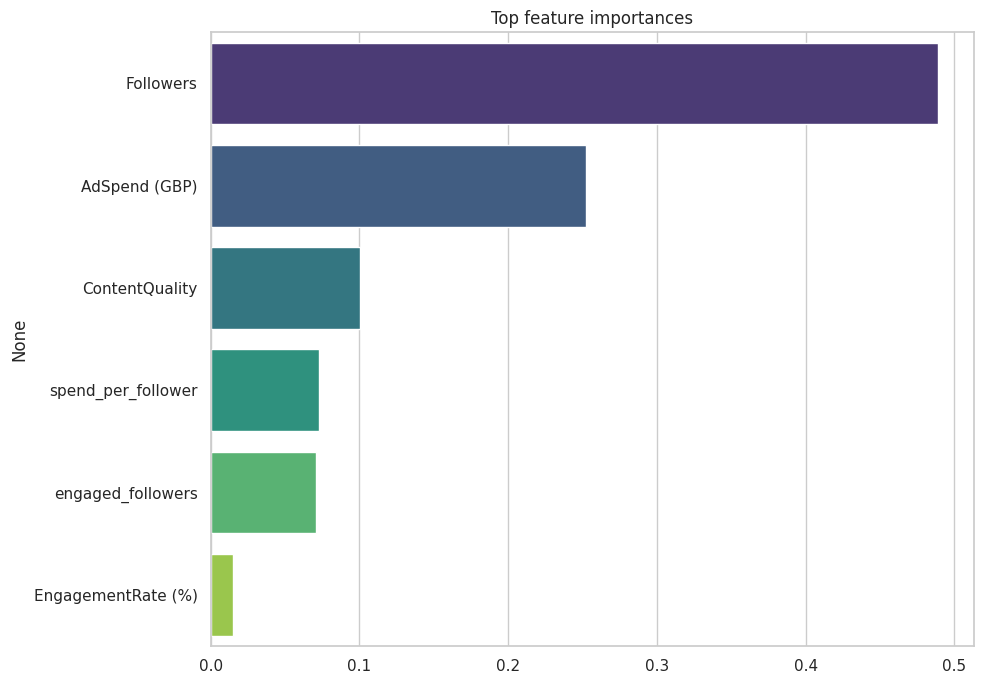

In [20]:
# Refit the selected model on the full training set
final_model = search.best_estimator_
final_model.fit(X, y)
print('Final model fitted on full training set.')

# Examine feature importance for tree-based models
model_step = final_model.named_steps['model']
if hasattr(model_step, 'feature_importances_'):
    importances = pd.Series(model_step.feature_importances_, index=feature_cols).sort_values(ascending=False)
    print('Top feature importances:')
    print(importances.head(15))

    plt.figure(figsize=(10, 7))
    sns.barplot(x=importances.values[:12], y=importances.index[:12], palette='viridis')
    plt.title('Top feature importances')
    plt.tight_layout()
    plt.show()
else:
    print('Model does not expose feature_importances_.')

## Cell 11: Reusable prediction pipeline

This function accepts raw messy campaign data and returns predicted sales. It performs all cleaning, feature engineering, and preprocessing automatically.

In [21]:
# Reusable function to predict sales directly from raw messy campaign data
def predict_sales(raw_df, fitted_model=final_model):
    df = raw_df.copy()

    # Remove target column if present to avoid leakage
    if 'Sales (Units)' in df.columns:
        df = df.drop(columns=['Sales (Units)'])

    # Clean raw data and engineer the same features used during training
    cleaned = clean_campaign_data(df)
    engineered = engineer_features(cleaned)
    engineered = engineered.reindex(columns=feature_cols)

    # Predict and ensure sales cannot be negative
    preds = fitted_model.predict(engineered)
    preds = np.clip(preds, a_min=0, a_max=None)

    return pd.Series(preds, index=raw_df.index, name='Predicted_Sales (Units)')


print('predict_sales function defined successfully.')

predict_sales function defined successfully.


In [22]:
# Quick sanity check on a random sample of raw rows
sample_indices = np.random.choice(len(train_raw), size=5, replace=False)
sample_raw = train_raw.iloc[sample_indices]
sample_preds = predict_sales(sample_raw)

print('Sample raw campaigns:')
print(sample_raw[['Followers', 'EngagementRate (%)', 'AdSpend (GBP)', 'ContentQuality']])
print('Sample predicted sales units:')
print(sample_preds.values)
print(train_raw.iloc[sample_indices]['Sales (Units)'].values)

Sample raw campaigns:
      Followers  EngagementRate (%)       AdSpend (GBP)  ContentQuality
396     49864.0  3.0799118505718495  2452.8857781206534        3.920995
5040   111374.0  1.4053286397499327   4824.823211335402        2.012963
1008    82303.0   1.469539746300395   5731.426512850697        9.608275
7135    24351.0   4.584919960582127   6192.873751050917        6.473073
4445    83496.0  1.5955053531293513   6354.374827120937        7.693496
Sample predicted sales units:
[10707.226 10113.772 10838.189  8205.789 11122.295]
[ 9301 11977 13505  6449  8465]


## Cell 12: Generate predictions on the test set

This final step creates predictions for the unseen test data and saves them to a CSV file for submission or reporting.

In [23]:
# Generate predictions for the full test set
test_predictions = predict_sales(test_raw)

submission = pd.DataFrame({
    'ID': test_raw['ID'].values if 'ID' in test_raw.columns else range(len(test_raw)),
    'Predicted_Sales (Units)': test_predictions.values
})

submission.to_csv('test_predictions.csv', index=False)

print('Predictions saved to test_predictions.csv')
print(submission.head(10))
print('Prediction summary:')
print(submission['Predicted_Sales (Units)'].describe())

Predictions saved to test_predictions.csv
     ID  Predicted_Sales (Units)
0  6252             11836.608398
1  4684              8770.636719
2  1731             10157.028320
3  4742             10634.295898
4  4521             11570.607422
5  6340              9525.065430
6   576             13451.562500
7  5202              8453.019531
8  6363             12727.088867
9   439              9986.038086
Prediction summary:
count     2000.000000
mean     10309.253906
std       2267.662598
min       3220.198730
25%       8836.195557
50%      10402.303223
75%      11841.653564
max      16718.050781
Name: Predicted_Sales (Units), dtype: float64


## Final notes

This notebook provides an end-to-end workflow for a real-world sales prediction problem from messy campaign data. The pipeline is reusable, easy to adapt, and can be used on future campaign datasets with the same schema. A good model in this task is not just about maximizing a single metric, it is also about building a pipeline that is reliable and explainable.